## Constructed a Neural network of input layer one hidden layer and one output layer 

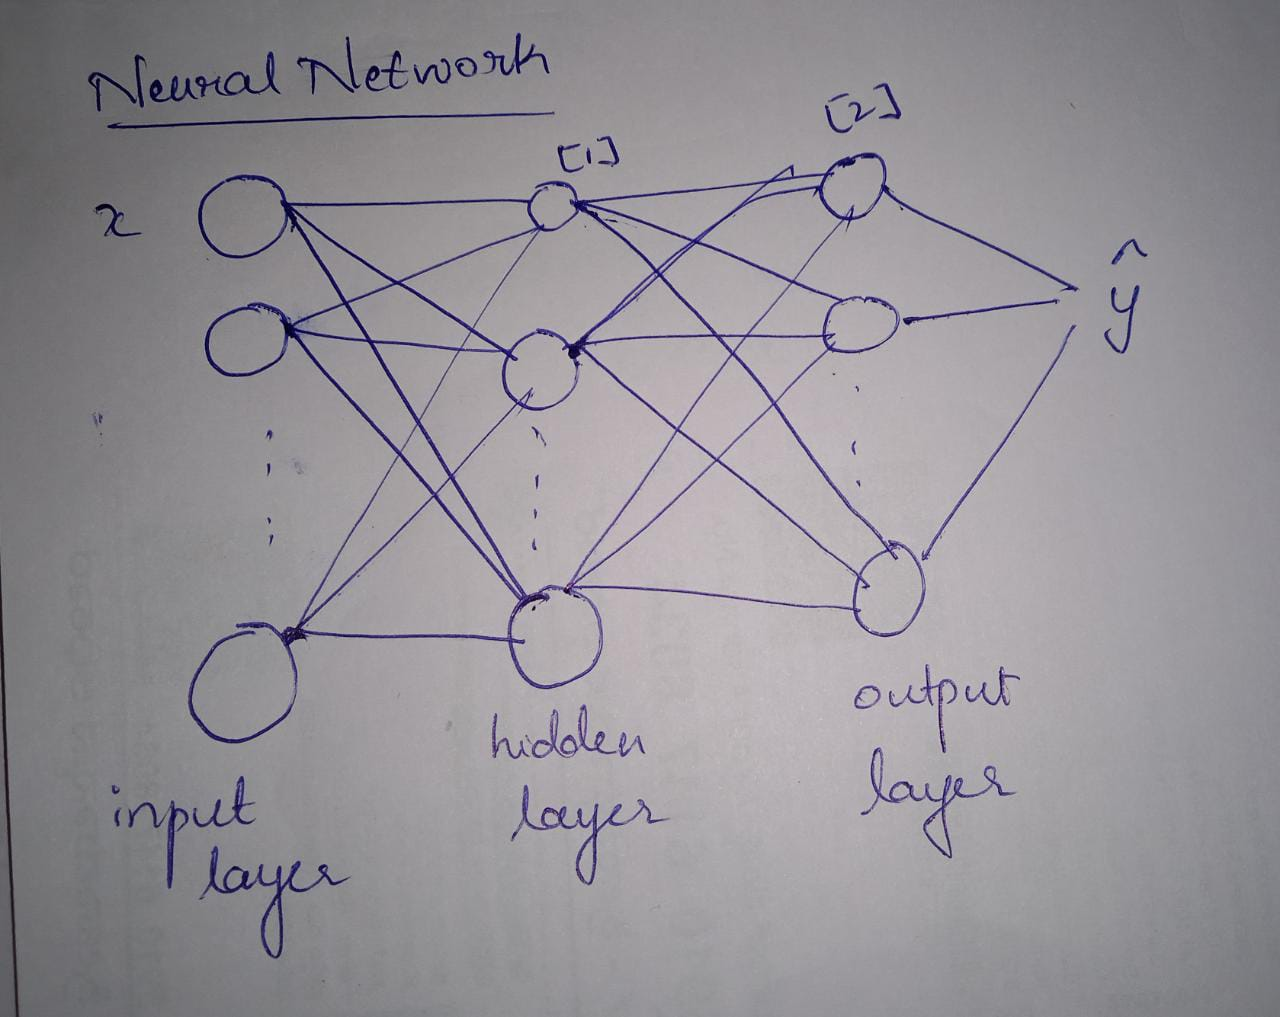

## Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Loading Dataset

In [2]:
data = pd.read_csv('mnsit.csv')
data.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### converting dataframe into numpy array

In [3]:
data = np.array(data)
m,n = data.shape
m,n

(42000, 785)

### Normalizing the dataset

In [4]:
np.random.shuffle(data)
data_dev = data[0:1000].T
x_dev = data_dev[1:n]
y_dev = data_dev[0]
x_dev = x_dev / 255.

data_train = data[1000:m].T
y_train = data_train[0]
x_train = data_train[1:n]

x_train = x_train/255.

In [5]:
y_train.shape

(41000,)

In [6]:
x_train.shape

(784, 41000)

### Initializing parameters such as w1 b1 w2 b2

In [7]:
def init_params():
    w1 = np.random.rand(10,784) - 0.5
    b1 = np.random.rand(10,1) - 0.5
    w2 = np.random.rand(10,10) - 0.5
    b2 = np.random.rand(10,1) - 0.5
    return w1,b1,w2,b2

### Rectified Linear Unit as an activation function

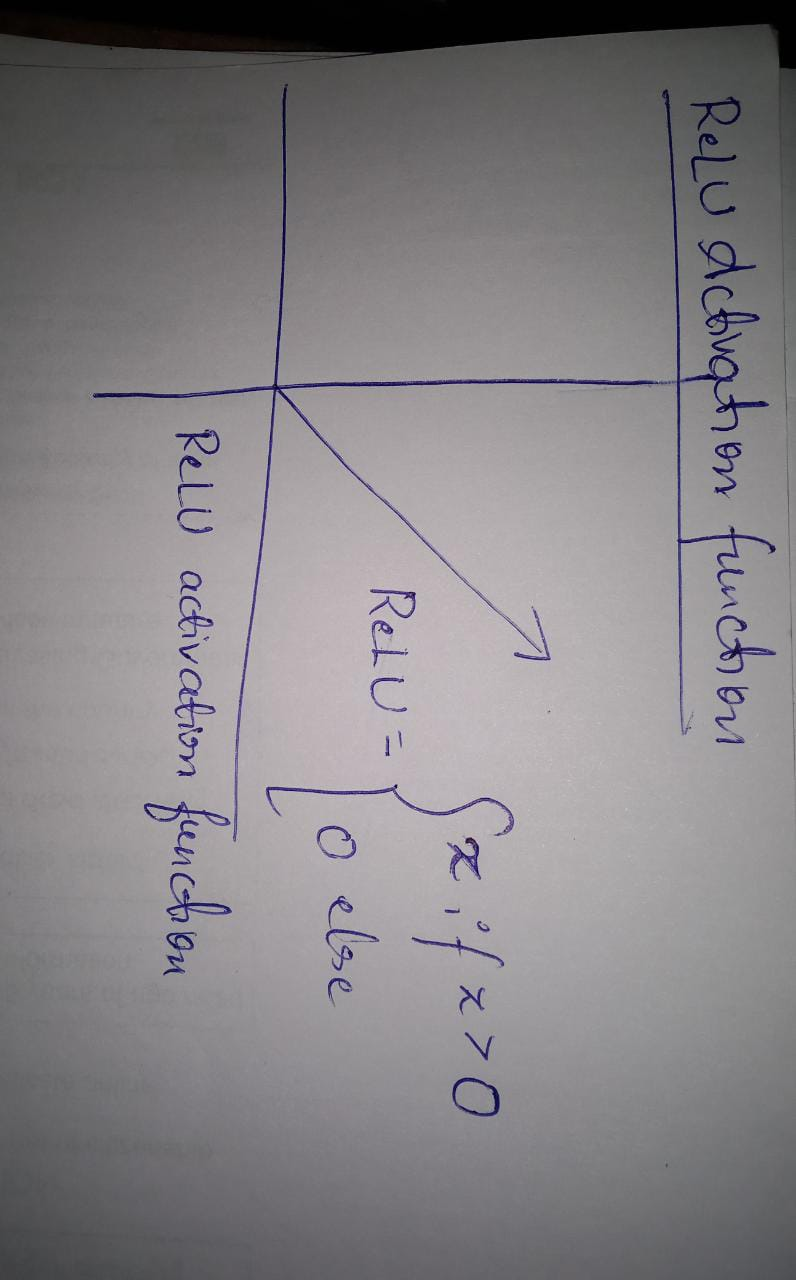

In [8]:
def ReLU(z):
    return np.maximum(z, 0)

### Softmax Activation function

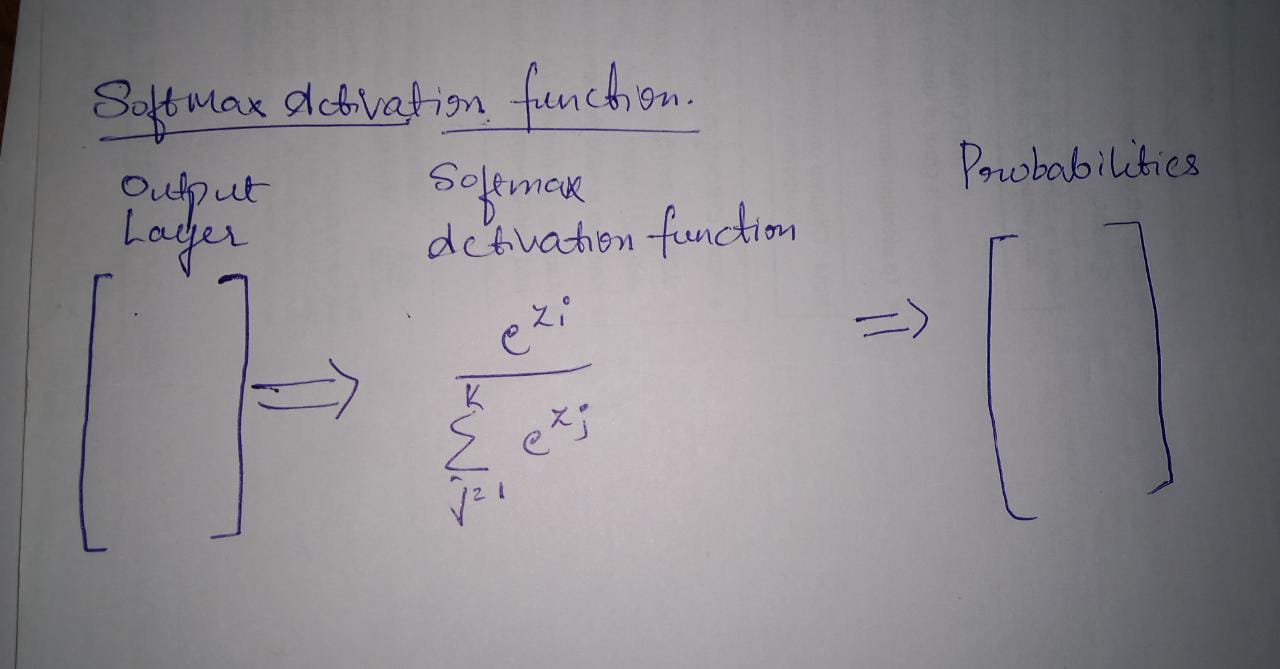

In [9]:
def softmax(Z):
    A = np.exp(Z) / sum(np.exp(Z))
    return A

### Forward propogation of the neural network

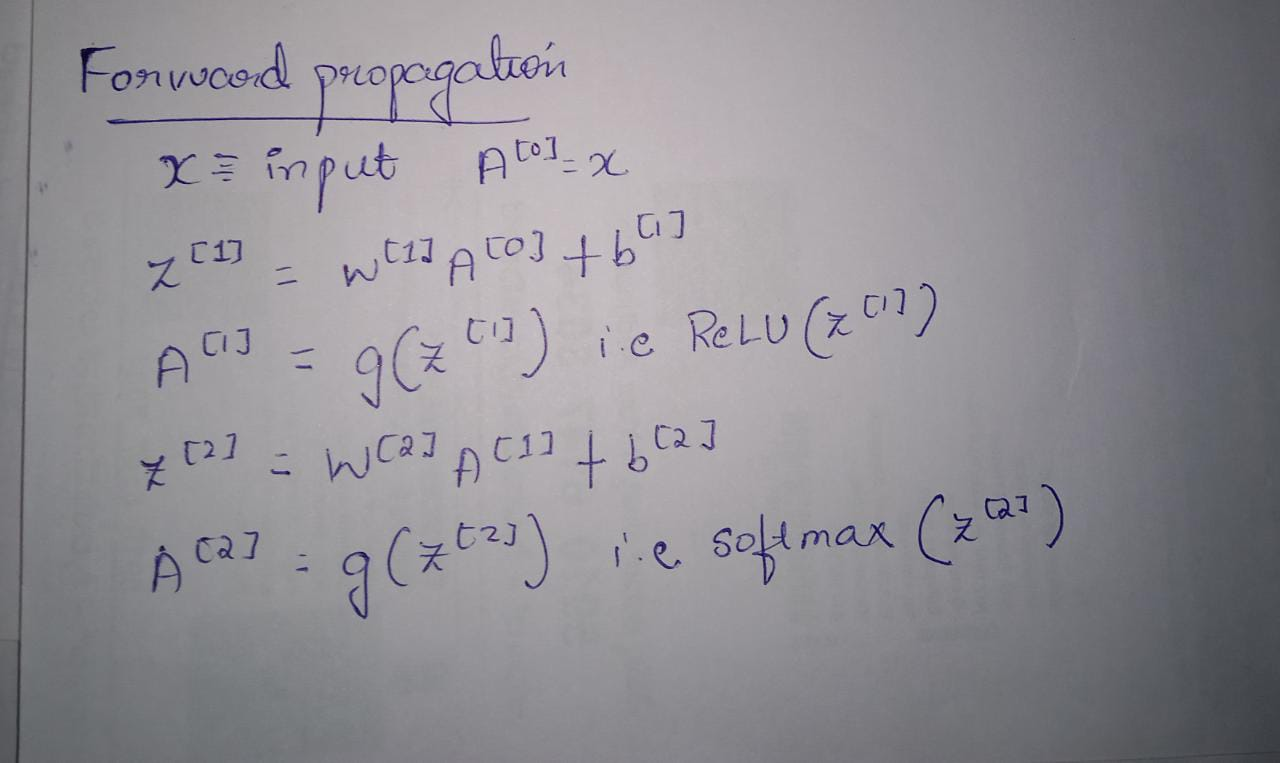

In [10]:
def forward_prop(w1,b1,w2,b2,x):
    z1 = w1.dot(x) + b1
    a1 = ReLU(z1)
    z2 = w2.dot(a1) + b2
    a2 = softmax(z2)
    return z1,a1,z2,a2

### one hot encoding of the target values

In [11]:
def one_hot(Y):
    one_hot_Y = np.zeros((Y.size, Y.max() + 1))
    one_hot_Y[np.arange(Y.size), Y] = 1
    one_hot_Y = one_hot_Y.T
    return one_hot_Y

### derivative of ReLU function

In [12]:
def deriv_relu(z):
    return z>0

### Back Propagation of the neural network 

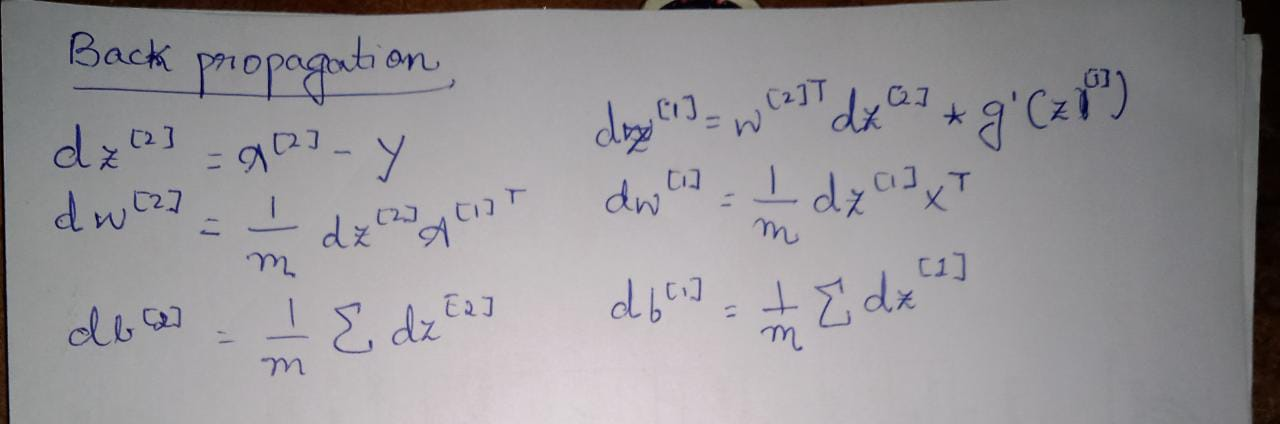

In [13]:
def back_prop(z1,a1,z2,a2,w1,w2,x,y):
    m = y.size
    one_hot_y = one_hot(y)
    dz2 = a2 - one_hot_y
    dw2 = 1 / m  * dz2.dot(a1.T)
   
    db2 = 1/m * np.sum(dz2)
    
    dz1 = w2.T.dot(dz2) * deriv_relu(z1)
    dw1 = 1/m * dz1.dot(x.T)
    
    db1 = 1/m * np.sum(dz1)
    
    return dw1,db1,dw2,db2

### prediction of the output

In [14]:
def get_predictions(a2):
    return np.argmax(a2,0)

### Accuracy

In [15]:
def get_accuracy(predictions,y):
    print(predictions,y)
    return np.sum(predictions == y)/y.size

### Updating the weights and biases

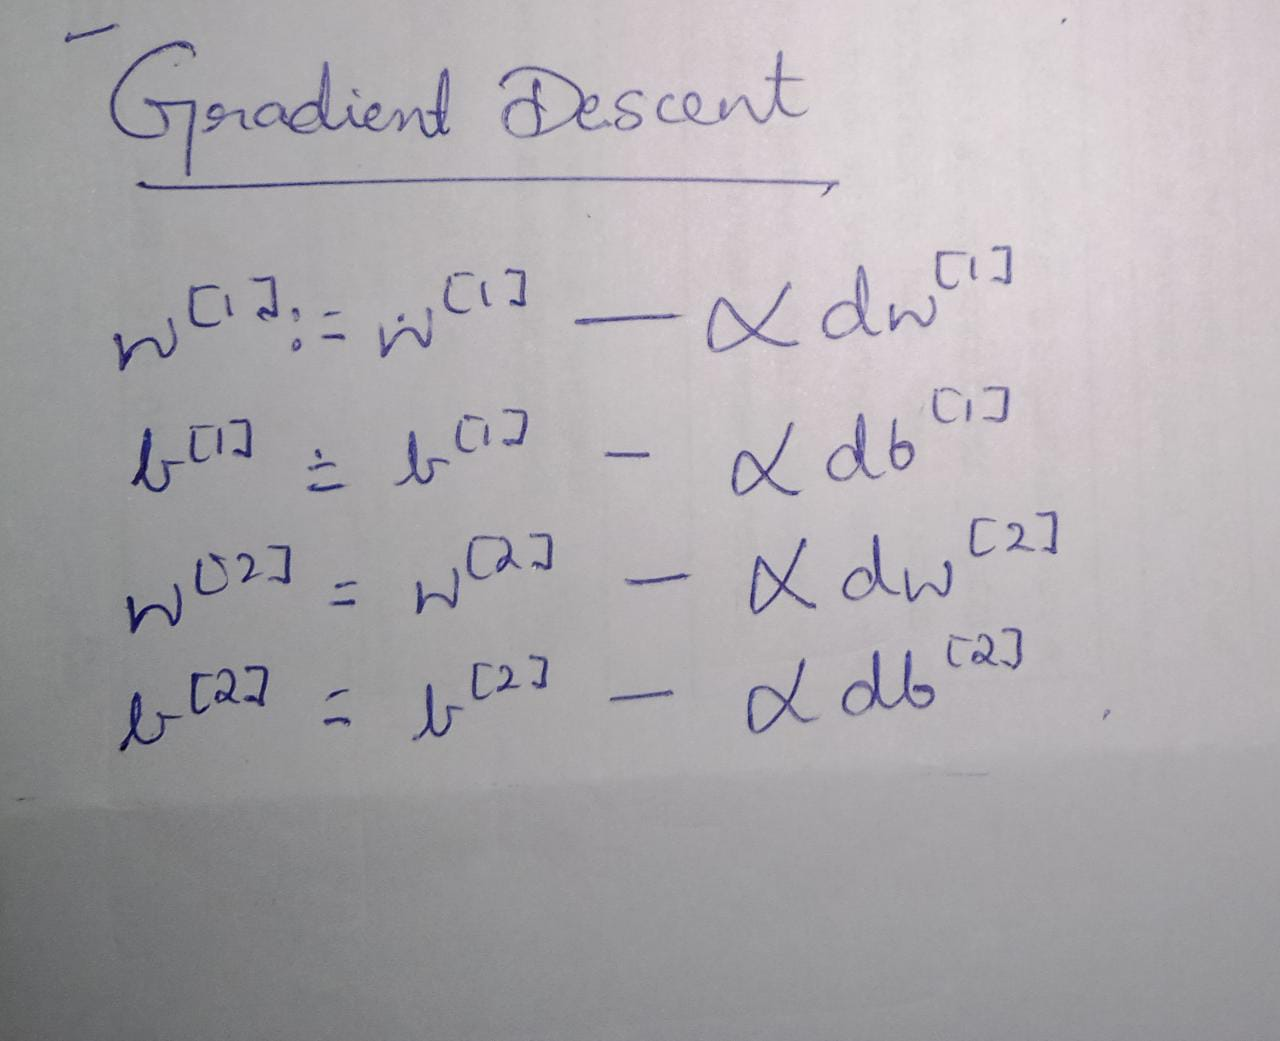

In [16]:
def update_params(w1, b1, w2, b2, dw1, db1, dw2, db2, alpha):
    w1 = w1 - alpha * dw1
    b1 = b1 - alpha * db1
    
    w2 = w2 - alpha * dw2
    b2 = b2 - alpha * db2
    
    return w1,b1,w2,b2

### Gradient descent function

In [17]:
best_accuracy = 0
def gradient_descent(x,y,iterations,alpha):
    global best_accuracy
    w1,b1,w2,b2 = init_params()
    for i in range(0,iterations):
        z1,a1,z2,a2 = forward_prop(w1,b1,w2,b2,x)
        dw1,db1,dw2,db2 = back_prop(z1,a1,z2,a2,w1,w2,x,y)
        w1,b1,w2,b2 = update_params(w1,b1,w2,b2,dw1,db1,dw2,db2,alpha)
        iter_accuracy = get_accuracy(get_predictions(a2),y)
        if iter_accuracy> best_accuracy:
            best_accuracy = iter_accuracy
        if i % 10 == 0 :
            print('Iteration: ',i)
            print('Accuracy; ',iter_accuracy)
    return w1,b1,w2,b2
    

In [18]:
w1,b1,w2,b2 = gradient_descent(x_train,y_train,1001,0.1)


[6 0 6 ... 7 9 1] [5 5 1 ... 6 1 7]
Iteration:  0
Accuracy;  0.0785609756097561
[5 0 6 ... 2 9 1] [5 5 1 ... 6 1 7]
[5 0 6 ... 2 9 1] [5 5 1 ... 6 1 7]
[5 0 6 ... 2 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 2 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
Iteration:  10
Accuracy;  0.16539024390243903
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[5 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
Iteration:  20
Accuracy;  0.2607560975609756
[1 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[1 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[1 0 3 ... 0 3 0] [5 5 1 ... 6 1 7]
[

[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
Iteration:  210
Accuracy;  0.7777560975609756
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
Iteration:  220
Accuracy;  0.7829268292682927
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 8 1 .

[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
Iteration:  410
Accuracy;  0.8382195121951219
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
Iteration:  420
Accuracy;  0.8396097560975609
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 .

[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
Iteration:  610
Accuracy;  0.8605121951219512
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
Iteration:  620
Accuracy;  0.8613170731707317
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
Iteration:  630
Accuracy;  0.8621463414634146
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7

[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
Iteration:  820
Accuracy;  0.8740243902439024
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
Iteration:  830
Accuracy;  0.8745121951219512
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 ... 6 1 9] [5 5 1 ... 6 1 7]
[5 5 1 .

### Accuracy

In [19]:
print('Accuracy of the model is: ',best_accuracy)

Accuracy of the model is:  0.8816829268292683


### Making predictions

In [20]:
def make_predictions(x, w1, b1, w2, b2):
    _, _, _, A2 = forward_prop(w1, b1, w2, b2, x)
    predictions = get_predictions(A2)
    return predictions

### Testing predictions

In [21]:
def test_prediction(index, W1, b1, W2, b2, x, y):
    current_image = x[:, index, None]
    prediction = make_predictions(x[:, index, None], W1, b1, W2, b2)
    label = y[index]
    print("Prediction: ", prediction)
    print("Label: ", label)
    
    current_image = current_image.reshape((28, 28)) * 255
    plt.gray()
    plt.imshow(current_image, interpolation='nearest')
    plt.show()

### Testing first output for test dataset 

Prediction:  [0]
Label:  0


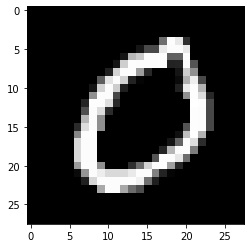

Prediction:  [2]
Label:  6


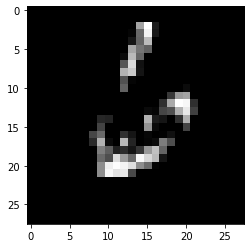

Prediction:  [7]
Label:  7


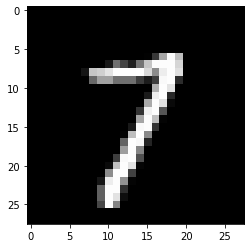

Prediction:  [3]
Label:  3


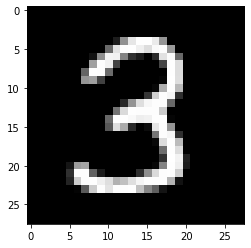

Prediction:  [6]
Label:  6


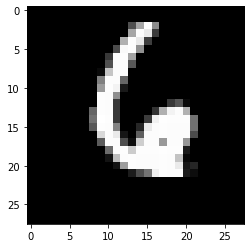

Prediction:  [1]
Label:  1


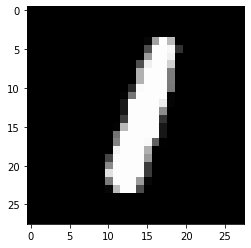

Prediction:  [7]
Label:  7


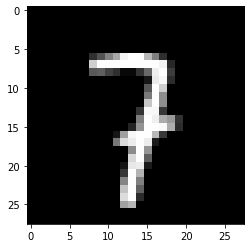

Prediction:  [4]
Label:  9


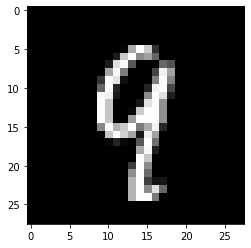

Prediction:  [1]
Label:  6


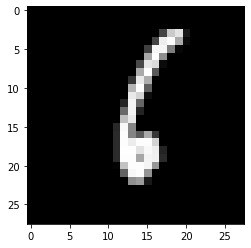

Prediction:  [3]
Label:  3


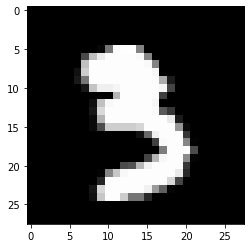

In [23]:
for i in range(10):
    test_prediction(i, w1, b1, w2, b2,x_dev,y_dev)